In [53]:
%precision 8
import numpy as np
import matplotlib.pyplot as plt

Before you turn this problem in, make sure everything runs as expected. First, restart the kernel (in the menubar, select Kernel $\rightarrow$ Restart) and then run all cells (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says YOUR CODE HERE or "YOUR ANSWER HERE", as well as your name and collaborators below:

# HW 2: BVP Problems 1

## Question 1

We can derive a non-uniform 3-point approximation to $u''(x_i)$ with the stencil
$$
    u''(x_i) \approx \frac{2}{\Delta x_i ( \Delta x_i + \Delta x_{i+1} )} U_{i-1} - \frac{2}{\Delta x_i \Delta x_{i+1}} U_{i} + \frac{2}{\Delta x_{i+1} ( \Delta x_i + \Delta x_{i+1} )} U_{i+1}
$$
where $\Delta x_i = x_i - x_{i-1}$.

**(a)** [10] Show that the truncation error for this approximation is 
$$
    \tau_i = \frac{1}{3} (\Delta x_{i+1} - \Delta x_i) u^{(3)}(x_i) + \frac{1}{12} \left (\frac{\Delta x_i^3 + \Delta x_{i+1}^3}{\Delta x_i + \Delta x_{i+1}} \right ) u^{(4)}(x_i) + \cdots.
$$
This leads us to believe that using this approach would be only first order accurate as 
$$
    \tau_i = \mathcal{O}(\max (\Delta x_i, \Delta x_{i+1} ) )
$$
if $\Delta x_i \neq \Delta x_{i+1}$.

Expand $u(x)$ around $x_i$ using Taylor Series, we have the following equations:

$$U_{i+1}=U_i+U_i'\Delta x_{i+1} +\dfrac{U_i'' \Delta x_{i+1}^2}{2}+\dfrac{U_i^{(3)}\Delta x_{i+1}^3}{6}+\dfrac{U_i^{(4)}\Delta x_{i+1}^4}{24}+\cdots$$

$$U_{i-1}=U_i-U_i'\Delta x_{i} +\dfrac{U_i'' \Delta x_{i}^2}{2}-\dfrac{U_i^{(3)}\Delta x_{i}^3}{6}+\dfrac{U_i^{(4)}\Delta x_{i}^4}{24}-\cdots$$

Hence,

$$
\begin{array}{rl}
&\displaystyle\frac{2}{\Delta x_i ( \Delta x_i + \Delta x_{i+1} )} U_{i-1} - \frac{2}{\Delta x_i \Delta x_{i+1}} U_{i} + \frac{2}{\Delta x_{i+1} ( \Delta x_i + \Delta x_{i+1} )} U_{i+1}\\
=&\displaystyle\dfrac{1}{\Delta x_i\Delta x_{i+1}(\Delta x_i+\Delta x_{i+1})}[(2\Delta x_{i+1}-2(\Delta x_i+\Delta x_{i+1})+2\Delta x_{i})U_i+2(-2\Delta x_i\Delta x_{i+1}+\Delta x_i\Delta x_{i+1})U_i'\\
&\displaystyle\left.+(\Delta x_i\Delta x_{i+1}^2+\Delta x_i^2\Delta x_{i+1})U_i''+\dfrac{U_i^{(3)}}{3}\left(\Delta x_i\Delta x_{i+1}^3+\Delta x_i^3\Delta x_{i+1}\right)+\dfrac{U_i^{(4)}}{12}(\Delta x_i^4\Delta x_{i+1}+\Delta x_i\Delta x_{i+1}^4)+\cdots\right]\\
=&\displaystyle U_i''-\left[\frac{1}{3} (\Delta x_{i+1} - \Delta x_i) u^{(3)}(x_i) + \frac{1}{12} \left (\frac{\Delta x_i^3 + \Delta x_{i+1}^3}{\Delta x_i + \Delta x_{i+1}} \right ) u^{(4)}(x_i) + \cdots.\right]\\
=&\displaystyle U_i''-\tau_i
\end{array}
$$

Therefore we proved

$$
u_i'' = \frac{2}{\Delta x_i ( \Delta x_i + \Delta x_{i+1} )} U_{i-1} - \frac{2}{\Delta x_i \Delta x_{i+1}} U_{i} + \frac{2}{\Delta x_{i+1} ( \Delta x_i + \Delta x_{i+1} )} U_{i+1}+\tau_i\\\approx \frac{2}{\Delta x_i ( \Delta x_i + \Delta x_{i+1} )} U_{i-1} - \frac{2}{\Delta x_i \Delta x_{i+1}} U_{i} + \frac{2}{\Delta x_{i+1} ( \Delta x_i + \Delta x_{i+1} )} U_{i+1}
$$

where $\tau=\mathcal{O}\left(\dfrac{1}{3}(x_{i+1}-x_i)\right)=\mathcal{O}(\max(\Delta x_i, \Delta x_{i+1}))$.

**(b)**  Implement a finite difference method based on the above discretization for the problem
$$
    u''(x) = e^x ~~~~ \Omega = [0, 1] \\
    u(0) = \alpha = 0 ~~~~ u(1) = \beta = 3
$$
whose true solution is
$$
    u(x) = e^x + (\sigma + 1) \times (x - 3) + \beta - e^3.
$$
Write the function so that it can take in a parameter `grid_type` that determines the type of grid to use.

In [54]:
def grid_points(a, b, m, grid_type='uniform'):
    """Returns a set of m grid points between a and b
    
    The parameter `grid_type` determines what the distribution of 
    points is.
     - grid_type = 'uniform' - Uniform distribution of points
     - grid_type = 'right_layer' - Clustered near right boundary
     - grid_type = 'random' - Randomly distributed
     - grid_type = 'chebyshev' - Chebyshev extreme points
    """
    # Computational grid
    z = np.linspace(0, 1, m + 2)
    
    if grid_type.lower() == "uniform":
        x = a + (b - a) * z
    elif grid_type.lower() == "right_layer":
        x = a + (b - a) * (1.0 - (1.0 - z)**2)
    elif grid_type.lower() == "random":
        x = np.empty(m + 2)
        x[1:-1] = a + (b - a) * np.sort(np.random.uniform(size=(m)))
        x[0] = a
        x[-1] = b
    elif grid_type.lower() == "chebyshev":
        x = a + (b - a) * 0.5 * (1.0 + np.cos(np.pi * (1.0 - z)))
    else:
        raise ValueError("Unknown grid type.")
    
    return x

In [55]:
def solve_nonuniform(a, b, alpha, beta, m, f, grid_type='uniform'):
    """Solve the ODE u'' = f(x)
    
    This function solves the ODE above using the grid specfied on the
    interval x \in [a, b] with boundary conditions u(a) = alpha and
    u(b) = beta.
    
    :Input:
     - *a* (float) - The beginning of the interval x \in [a, b]
     - *b* (float) - The end of the interval x \in [a, b]
     - *alpha* (float) - Value that defines the BC at x = a
     - *beta* (float) - Value that defines the BC at x = b
     - *m* (int) - Number of grid points to use
     - *f* (func) - Right hand side function defined in the ODE
     - *grid_type* (string) - Type of grid to use
     
    :Output:
     - *x* (ndarray) - Location of grid points used including boundaries
     - *U* (ndarray) - Solution array including boundary conditions (m + 2)
    """
    
    # Begin Solution Here
    # f = lambda x: np.exp(x)
    xs = grid_points(a, b, m, grid_type)
    dxs = xs[1:] - xs[:-1]
    A = np.diag(-2 * np.ones(m)) \
        + 2 * np.diag(dxs[:-2] / (dxs[:-2] + dxs[1:-1]), 1) \
        + 2 * np.diag(dxs[2:] / (dxs[1:-1] + dxs[2:]), -1)

    b = f(xs[1:-1]) * dxs[1:] * dxs[:-1]
    b[0] -= 2 * dxs[1] / (dxs[0] + dxs[1]) * alpha
    b[-1] -= 2 * dxs[-2] / (dxs[-2] + dxs[-1]) * beta

    x = xs
    U = np.array([0.0] * (m + 2))
    U[1:-1] = np.linalg.solve(A, b)
    U[0] = alpha
    U[-1] = beta
    return x, U

1.2677943269118485e-05


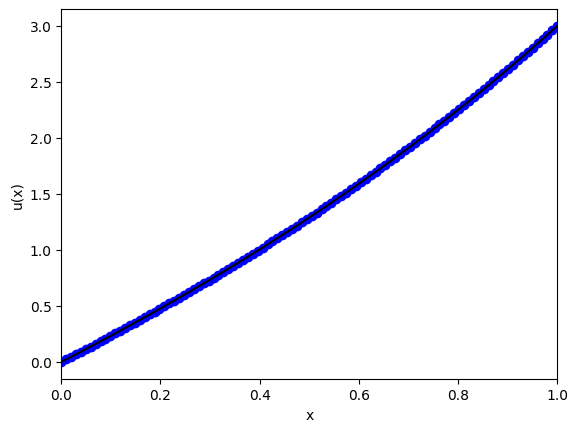

Success!


In [56]:
a = 0.0
b = 1.0
alpha = 0.0
beta = 3.0
f = lambda x: np.exp(x)
u_true = lambda x: (4.0 - np.exp(1.0)) * x - 1.0 + np.exp(x)
x, U = solve_nonuniform(a, b, alpha, beta, 100, f, grid_type='uniform')
print(np.linalg.norm(u_true(x) - U, ord=2))
fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(x, U, 'bo')
axes.plot(x, u_true(x), 'k')
axes.set_xlabel("x")
axes.set_ylabel("u(x)")
axes.set_xlim((a, b))
plt.show()
assert(np.linalg.norm(u_true(x) - U, ord=2) < 1e-4)
print("Success!")

**(c)** [10] We would expect in general then that we would see only 1st order convergence if we let `grid_type = 'random'`.  Analyze the convergence of the method using each of the types of point distributions available in the function `grid_points`.  Use the $\Delta x$ computed from the uniform grid point distribution.

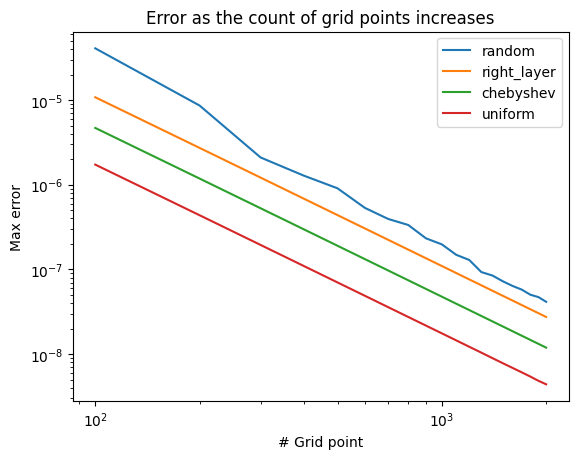

In [57]:
# Problem setup
a = 0.0
b = 1.0
alpha = 0.0
beta = 3.0
f = lambda x: np.exp(x)
u_true = lambda x: (4.0 - np.exp(1.0)) * x - 1.0 + np.exp(x)

# Begin Solution Here
fig = plt.figure()
for type in ["random", "right_layer", "chebyshev", "uniform"]:
    ms = list(range(100, 2001, 100))
    errs = []
    if type != "random":
        for m in ms:
            x, U = solve_nonuniform(a, b, alpha, beta, m, f, grid_type=type)
            errs.append(np.linalg.norm(u_true(x) - U, ord=np.inf))
        # print(type, errs)
        plt.plot(ms, errs, label=type)
    else:
        N = 10
        errs = [[] for _ in range(N)]
        for i in range(N): # take the average for random
            for m in ms:
                np.random.seed(i)
                x, U = solve_nonuniform(a, b, alpha, beta, m, f, grid_type=type)
                errs[i].append(np.linalg.norm(u_true(x) - U, ord=np.inf))
        plt.plot(ms, np.mean(errs, axis=0), label=type)
plt.yscale("log")
plt.xscale("log")
plt.title("Error as the count of grid points increases")
plt.xlabel("# Grid point")
plt.ylabel("Max error")
plt.legend()
plt.show()

1. From the graph, we can see that for each grid generator, the convergence order is always of 1st order (a line in log-log plot of errors). Among them, uniform method is the best, then chebyshev, then right_layer, and random is the worst.
2. Theoreticly, random generator will have the same convergence order as the uniform generator, since grid points are generated using uniform distributed random number engine. Other methods have similar conclusions, since each interval length changes linearly as the count of grid point increases.

## Question 2

Consider the convection-diffusion problem defined by
$$
    u_t + au_x = \kappa u_{xx} + \psi(x)
$$
This is similar to the heat conduction problem except that we also have a convective term $a~u_x$.  You can think of $u(x,t)$ as describing the distribution of dye in a stream flowing at velocity $a$ where $\kappa$ describes how quickly the dye diffuses and $\psi(x)$ represents dye being added to the stream.

Considering the steady state solution of the problem above leads to the ODE
$$
    \epsilon u''(x) - u'(x) = f(x)
$$
where $\epsilon$ represents the relative strength of the advective and diffusive effects.

We will solve this problem with the domain and boundary conditions
$$
    \Omega = [0, 1] ~~~~ u(0)=\alpha ~~~~ u(1)=\beta ~~~~ f(x) = -1
$$
whose true solution is
$$
    u(x) = \alpha + x + (\beta - \alpha -1) \left( \frac{e^{x / \epsilon} - 1}{e^{1 / \epsilon} - 1} \right ).
$$

**(a)** Discretize the boundary value problem presented using at least second order finite difference methods.  Make sure to pick the appropriate finite difference approach at the boundaries.

Here we use 2nd order centered difference approximations on uniform grid ($n + 2$ grid points, $\Delta x = \dfrac{b - a}{n + 1}$) to solve the problem. We'd have the following approximations for a function $u(x)$:

$$ u''(x_i) = u_i'' = \dfrac{u_{i+1}-2u_i+u_{i-1}}{\Delta x^2}, \quad u'(x_i) = u_i' = \dfrac{u_{i+1} - u_{i-1}}{2\Delta x}, \quad 1\leqslant i \leqslant n$$

with boundary conditions $u_0=\alpha, u_{n+1}=\beta$. We'll get $n$ equations.

Let $i = 1$, we have left boundary equation:

$$
\varepsilon\dfrac{u_2-2u_1}{\Delta x} - \dfrac{u_2}{2} = f_1\Delta x - \dfrac{u_0}{2} - \varepsilon\dfrac{u_0}{\Delta x}
$$

Let $i = n$, we have right boundary equation:

$$
\varepsilon\dfrac{-2u_n + u_{n-1}}{\Delta x} - \dfrac{-u_{n-1}}{2} = f_n\Delta x + \dfrac{u_{n+1}}{2} - \varepsilon\dfrac{u_{n+1}}{\Delta x}
$$

For other $i$s, we have

$$
\varepsilon\dfrac{u_{i+1}-2u_i+u_{i-1}}{\Delta x} - \dfrac{u_{i+1} - u_{i-1}}{2} = f_i\Delta x
$$


In [58]:
def solve_adv_diff(alpha, beta, epsilon, m):
    """Solve the steady-state advection-diffusion problem
    
    :Input
     - *alpha* (float) - Value that defines the BC at x = 0
     - *beta* (float) - Value that defines the BC at x = 1
     - *epsilon* (float) - The ratio of the advection speed and diffusivity
     - *m* (int) - Number of grid points to use
     
    :Output:
     - *x* (ndarray) - Location of grid points used including boundaries
     - *U* (ndarray) - Solution array including boundary conditions (m + 2)
    """
    
    a = 0
    b = 1
    h = (b - a) / (m + 1)

    x = grid_points(a, b, m, 'uniform')
    A = np.diag((-2 * epsilon / h) * np.ones(m)) \
        + np.diag((epsilon / h - 1 / 2.) * np.ones(m - 1), 1) \
        + np.diag((epsilon / h + 1 / 2.) * np.ones(m - 1), -1)

    f = lambda _: -1
    y = np.array(list(map(f, x[1:-1]))) * h
    y[0] -= alpha / 2. + epsilon / h * alpha
    y[-1] += beta / 2. - epsilon * beta / h

    U = np.array([0.0] * len(x))
    U[0] = alpha
    U[-1] = beta
    U[1:-1] = np.linalg.solve(A, y)

    return x, U

8.130805094105495e-05
Success!


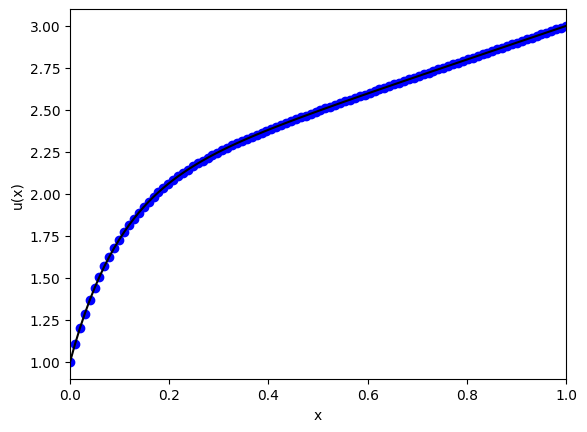

In [59]:
alpha = 1.0
beta = 3.0
epsilon = -0.1
u_true = lambda x: alpha + x + (beta - alpha - 1.0) * (np.exp(x / epsilon) - 1.0) / (np.exp(1.0 / epsilon) - 1.0)
x, U = solve_adv_diff(alpha, beta, epsilon, 100)

fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(x, U, 'bo')
axes.plot(x, u_true(x), 'k')
axes.set_xlabel("x")
axes.set_ylabel("u(x)")
axes.set_xlim((0.0, 1.0))

error = np.linalg.norm((x[1] - x[0]) * (U - u_true(x)), ord=1)
# print((x[1] - x[0]) * (U - u_true(x)))
print(error)
assert(error < 1e-4)
print("Success!")

**(b)** [10] Using your function from part (a) explore the parameter space a bit by varying $m$ and $\epsilon$.  Suggested values to explore include $m \in [10, 100]$ and $\epsilon \in [-0.01, -1.0]$.

Describe what you observe with both plots and written observations.  In particular do your solutions seem physically reasonable?  If your code has difficulties explain why it might be having issues.

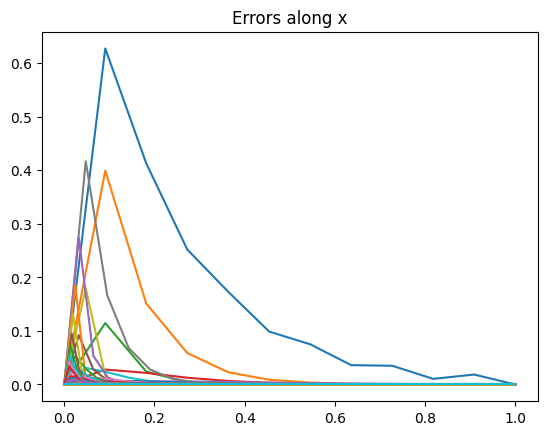

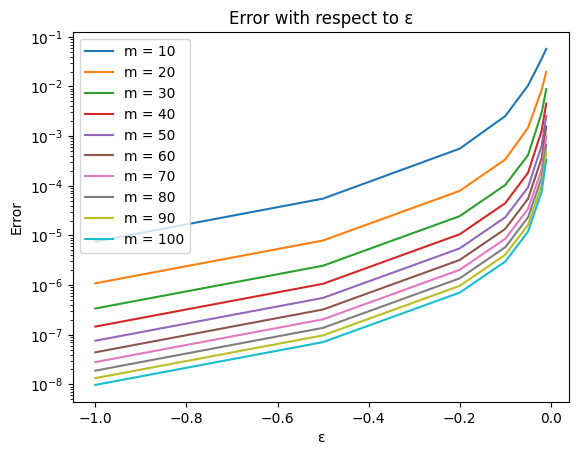

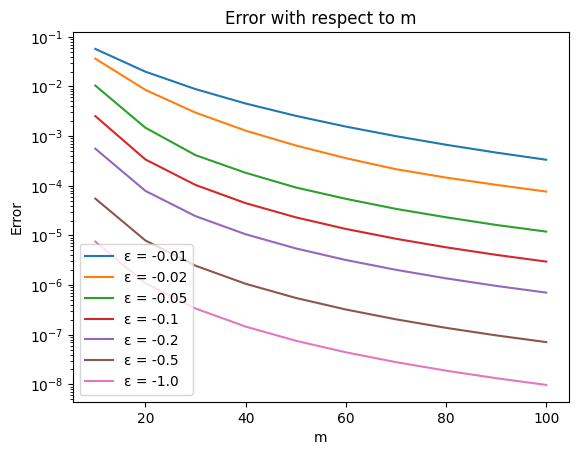

In [60]:
a = 0.0
b = 1.0
alpha = 1.0
beta = 3.0

eps = [-0.01, -0.02, -0.05, -0.1, -0.2, -0.5, -1.0]
ms = list(range(10, 101, 10))

# over domain
errs = {}
plt.figure(1)
for m in ms:
    for epsilon in eps:
        u_true = lambda x: alpha + x + (beta - alpha - 1.0) * (np.exp(x / epsilon) - 1.0) / (np.exp(1.0 / epsilon) - 1.0)
        x, U = solve_adv_diff(alpha, beta, epsilon, m)
        real_U = np.array(list(map(u_true, x)))

        plt.plot(x, np.abs(U - u_true(x)), label=str((m, epsilon)))
        err = np.linalg.norm((x[1] - x[0]) * (U - u_true(x)), ord=np.inf)
        errs[(m, epsilon)] = err
        # print("m, epsilon, error: ", m, epsilon, err)
# plt.legend()
plt.title("Errors along x")
plt.show()

# epsilon changes
plt.figure(2)
for m in ms:
    sec_errs = [errs[(m, e)] for e in eps]
    plt.plot(eps, sec_errs, label="m = " + str(m))
plt.title("Error with respect to ε")
plt.yscale("log")
plt.xlabel("ε")
plt.ylabel("Error")
plt.legend()
plt.show()

# m changes
plt.figure(3)
for e in eps:
    sec_errs = [errs[(m, e)] for m in ms]
    plt.plot(ms, sec_errs, label="ε = " + str(e))
plt.title("Error with respect to m")
plt.yscale("log")
plt.xlabel("m")
plt.ylabel("Error")
plt.legend()
plt.show()

From the graph we can see that

- fix $m$, then the absolute error decreases as $|\varepsilon|$ increases (possibly quadratic).
- fix $\varepsilon$, the absolute error decreases as $m$ increases (possibly quadratic).

## Question 3

Consider the following BVP:
$$
    u''(x) + u(x) = 0 \quad \quad x \in \Omega = (a, b) \\
    u(a) = \alpha \quad u(b) = \beta
$$
where $L = b - a$.

**(a)** [10] What is the exact solution of the BVP?

The characteristic equation to the BVP is $\lambda^2+1=0\ \Rightarrow\ \lambda_1 = i,\lambda_2=-i$, hence the solution has the form $u(x)=C_1\cos x+C_2\sin x$. Consider the BC, $u(a)=\alpha,u(b)=\beta$, we have

$$
\left\{\begin{array}{l}
C_1\cos a + C_2\sin a = \alpha\\
C_1\cos b + C_2\sin b = \beta
\end{array}\right.\quad\Rightarrow\quad
\left\{\begin{array}{l}
C_1 = \dfrac{\alpha\sin b-\beta\sin a}{\sin(b-a)}\\
C_2 = \dfrac{\alpha\cos b-\beta\cos a}{\sin(a-b)}
\end{array}\right.\quad\Rightarrow\quad
u(x)= \dfrac{\alpha\sin b-\beta\sin a}{\sin(b-a)}\cos x+\dfrac{\alpha\cos b-\beta\cos a}{\sin(a-b)}\sin x
$$

**(b)** [15] Write a function that solves this equation using a finite difference approximation.

In [61]:
import scipy.sparse as ss
import scipy.sparse.linalg as ssl

def solve_linear_pendulum(a, b, alpha, beta, m):
    """Solve u'' + u = 0 with x \in (a, b) and u(a) = \alpha, u(b) = \beta
    
    Returns the points the solution was approximated at including the boundaries and
    the solution
    """
    
    h = (b - a) / (m + 1)
    x = grid_points(a, b, m, 'uniform')
    A = None
    if m <= 1000:
        A = np.diag((-2 + h * h) * np.ones(m)) \
            + np.diag(np.ones(m - 1), 1) \
            + np.diag(np.ones(m - 1), -1)
    else:
        A = ss.diags([(-2 + h * h) * np.ones(m), np.ones(m - 1), np.ones(m - 1)], [0, 1, -1])

    f = lambda _: 0.0
    y = np.array(list(map(f, x[1:-1]))) * h
    y[0] -= alpha
    y[-1] -= beta

    U = np.array([0.0] * len(x))
    U[0] = alpha
    U[-1] = beta
    if m <= 1000:
        U[1:-1] = np.linalg.solve(A, y)
    else:
        U[1:-1] = ssl.spsolve(A, y)

    return x, U

def get_pendulum_A(a, b, m):
    h = (b - a) / (m + 1)
    A = None
    if m <= 1000:
        A = np.diag((-2 + h * h) * np.ones(m)) \
            + np.diag(np.ones(m - 1), 1) \
            + np.diag(np.ones(m - 1), -1)
    else:
        A = ss.diags([(-2 + h * h) * np.ones(m), np.ones(m - 1), np.ones(m - 1)], [0, 1, -1])
    return A

Error =  2.1017625588265422e-06
Success!


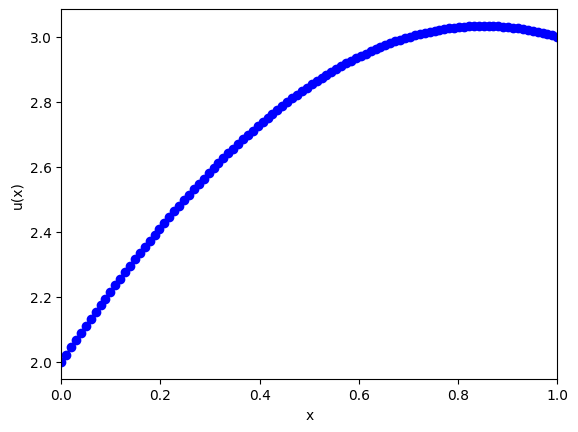

In [62]:
a = 0.0
b = 1.0
alpha = 2.0
beta = 3.0
C1 = (alpha - beta * np.sin(a) / np.sin(b)) / (np.cos(a) - np.sin(a) / np.tan(b))
C2 = beta / np.sin(b) - C1 / np.tan(b)
u_true = lambda x: C1 * np.cos(x) + C2 * np.sin(x)
x, U = solve_linear_pendulum(a, b, alpha, beta, 100)
fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(x, u_true(x), 'k')
axes.plot(x, U, 'ob')
axes.set_xlim(a, b)
axes.set_xlabel("x")
axes.set_ylabel("u(x)")
error = np.linalg.norm((x[1] - x[0]) * (U - u_true(x)), ord=1)
print("Error = ", error)
assert(error < 1e-5)
print("Success!")

**(c)** [5] Let $a=0$ and $b=\pi$.  For what values of $\alpha$ and $\beta$ does this BVP have solutions?  Sketch out a family of solutions in the case of infinite numbers of solutions.

Let $a=0,b=\pi$, we'll have $C_1 = \alpha, -C_1 = \beta$ when calculating the first subproblem. Therefore, this BVP has solutions iff. $\alpha=-\beta=\lambda$. We'll draw a bunch of solutions w.r.t $\lambda=\alpha$.

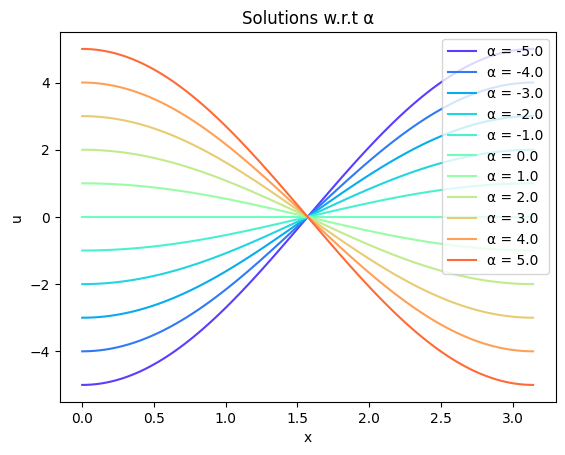

In [63]:
# Solution Here!
fig = plt.figure()
lambdas = np.linspace(-5, 5, 11)
cm = plt.get_cmap("rainbow")
for lam in lambdas:
    x, U = solve_linear_pendulum(0, np.pi, lam, -lam, 100)
    plt.plot(x, U, label="α = " + str(lam)[:5], color=cm(int(20 * (lam + 6))))
plt.legend()
plt.xlabel("x")
plt.ylabel("u")
plt.title("Solutions w.r.t α")
plt.show()

**(d)** [5] What happens numerically for the values $a = 0$, $b = \pi$, $\alpha = 1$, $\beta = -1$ as $\Delta x \rightarrow 0$?  Also try with $\alpha = \beta = 1$.

1. By the subproblems above, if $a=0,b=\pi,\alpha=1,\beta=-1$, then the solution will be $u(x)=\cos x+C\sin x=\sqrt{1+C^2}\cos(x-\arctan C)$, where $C\in\mathbb{R}$, hence as $\Delta x\to 0$, the solution should converge to $u(x)=\cos x$. But for computers, when $\Delta x$ gets smaller and smaller, the relative errors due to truncation will expand, hence to some point, the errors will raise again.
2. If $\alpha=\beta=1$, there will be no solution, hence the result will not converge no matter how $\Delta x$ is.

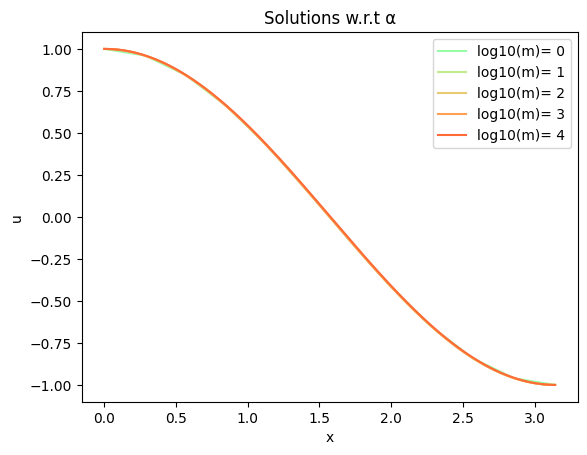

In [64]:
# Solution Here
# alpha = 1, beta = -1
fig = plt.figure()
ms = 10 ** np.array(list(range(1, 6, 1)))
cm = plt.get_cmap("rainbow")
i = 0

errs = []
u_true = lambda x: np.cos(x)
for m in ms:
    i += 1
    x, U = solve_linear_pendulum(0, np.pi, 1, -1, m)
    plt.plot(x, U, label="log10(m)= " + str(i - 1), color=cm(int(20 * (i + 6))))

    err = np.linalg.norm((x[1] - x[0]) * (U - u_true(x)), ord=np.inf)
    errs.append(err)
plt.legend()
plt.xlabel("x")
plt.ylabel("u")
plt.title("Solutions w.r.t α")
plt.show()

[0.000531513761983435, 7.036550523656977e-07, 9.418662625534574e-10, 1.727563916854674e-07, 1.7832632193760698e-07]


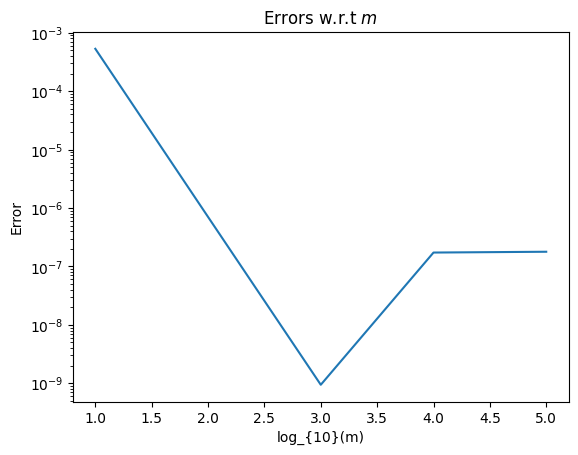

In [65]:
print(errs)
fig = plt.figure()
plt.plot(np.log10(ms), errs)
plt.title("Errors w.r.t $m$")
plt.yscale("log")
plt.xlabel("log_{10}(m)")
plt.ylabel("Error")
plt.show()

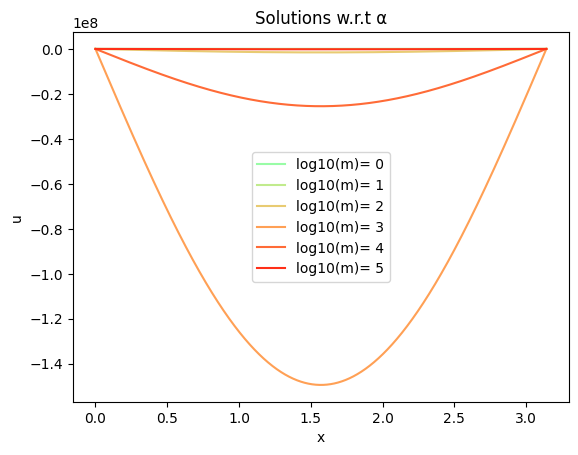

In [66]:
# Solution Here
# alpha = 1, beta = 1
fig = plt.figure()
ms = 10 ** np.array(list(range(1, 7, 1)))
cm = plt.get_cmap("rainbow")
i = 0

errs = []
u_true = lambda x: np.cos(x)
for m in ms:
    i += 1
    x, U = solve_linear_pendulum(0, np.pi, 1, 1, m)
    plt.plot(x, U, label="log10(m)= " + str(i - 1), color=cm(int(20 * (i + 6))))

    err = np.linalg.norm((x[1] - x[0]) * (U - u_true(x)), ord=np.inf)
    errs.append(err)
plt.legend()
plt.xlabel("x")
plt.ylabel("u")
plt.title("Solutions w.r.t α")
plt.show()

**(e)** [5] You might expect the linear system in part (c) to be singular since the boundary value problem is not well posed.  Clearly this does not seem to be the case as we are finding solutions.  One argument for why this is the case is that the finite discretization leads to a system that is solvable.  Let's investigate this computational by computing some quantities related to the matrix $A$ and show what their behavior is as $\Delta x \rightarrow 0$:
 - compute the eigenvalues of the matrix $A$,
 - compute the $L_2$ norm of $A^{-1}$, and
 - compute the condition number of the matrix $A$.
Comment on what you observe.

In [67]:
import scipy

# Solution Here
fig = plt.figure()
ms = np.array([10, 20, 50, 100, 200, 500, 1000])
cm = plt.get_cmap("rainbow")
i = 0

errs = []
u_true = lambda x: np.cos(x)
for m in ms:
    i += 1
    A = get_pendulum_A(1, 1, m)
    eigvs = scipy.linalg.eigvals(A)
    nm = np.linalg.norm(np.linalg.inv(A), ord=2)
    cd = np.linalg.cond(A, p=2)
    print("log10(m): {:.4f} mean: {:.4f} variance: {:.4f} L2 norm of inv(A): {:.4f} cond of A: {:.4f}"
          .format(np.log10(m), np.mean(eigvs), np.var(eigvs), nm, cd))
# plt.legend()
# plt.xlabel("x")
# plt.ylabel("u")
# plt.title("Solutions w.r.t α")
# plt.show()

log10(m): 1.0000 mean: -2.0000+0.0000j variance: 1.8000 L2 norm of inv(A): 12.3435 cond of A: 48.3742
log10(m): 1.3010 mean: -2.0000+0.0000j variance: 1.9000 L2 norm of inv(A): 44.7661 cond of A: 178.0643
log10(m): 1.6990 mean: -2.0000+0.0000j variance: 1.9600 L2 norm of inv(A): 263.6197 cond of A: 1053.4790
log10(m): 2.0000 mean: -2.0000+0.0000j variance: 1.9800 L2 norm of inv(A): 1033.6607 cond of A: 4133.6429
log10(m): 2.3010 mean: -2.0000+0.0000j variance: 1.9900 L2 norm of inv(A): 4093.5605 cond of A: 16373.2419
log10(m): 2.6990 mean: -2.0000+0.0000j variance: 1.9960 L2 norm of inv(A): 25431.8017 cond of A: 101726.2070
log10(m): 3.0000 mean: -2.0000+0.0000j variance: 1.9980 L2 norm of inv(A): 101524.0107 cond of A: 406095.0427


<Figure size 640x480 with 0 Axes>

We can see from the results that

- the mean of the eigenvalues of $A$ keep steady, and the distribution of the eigenvalues becomes more and more sparse slowly.
- the norm of $A^{-1}$ and condition number of $A$ climbs up quickly as $\Delta x$ decreases. This indicates that computing solutions for $Ax=y$ will becomes more errorful. Hence as $\Delta x \to 0$, at some time, the error will also climb up.